# Improving Fiction / Nonfiction Classification

In `text-classification.ipynb`, zero-shot classification with `facebook/bart-large-mnli` labelled books as
**Fiction** or **Nonfiction** with **77.8% accuracy** on a 600-book test set. That model never saw a single
labelled example.

This notebook tests whether a **supervised classifier trained on the books we already have labels for**
does better, and if so, uses it to re-label the 1,454 books that had no category.

**Keeping the comparison fair**
- The **test set is the exact same 600 books** (the first 300 Fiction + first 300 Nonfiction) used for the
  zero-shot score. They are never used for training or model selection.
- The model configuration is chosen with **5-fold cross-validation on the training set only**. The test set
  is scored once, at the end.

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import chromadb
from scipy.stats import binomtest
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression, LogisticRegressionCV
from sklearn.metrics import accuracy_score, balanced_accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from transformers import pipeline

warnings.filterwarnings("ignore")

DATA_DIR = Path("../data")
PROCESSED = DATA_DIR / "processed"
SEED = 42

## 1. Data and labels

The same category mapping as `text-classification.ipynb`. Books whose original category is not in the mapping
are the **unlabelled** books that need a prediction.

In [2]:
books = pd.read_csv(PROCESSED / "books_cleaned.csv")

category_mapping = {'Fiction' : "Fiction",
 'Juvenile Fiction': "Children's Fiction",
 'Biography & Autobiography': "Nonfiction",
 'History': "Nonfiction",
 'Literary Criticism': "Nonfiction",
 'Philosophy': "Nonfiction",
 'Religion': "Nonfiction",
 'Comics & Graphic Novels': "Fiction",
 'Drama': "Fiction",
 'Juvenile Nonfiction': "Children's Nonfiction",
 'Science': "Nonfiction",
 'Poetry': "Fiction"}

books["simple_categories"] = books["categories"].map(category_mapping)
# 1 = Fiction, 0 = Nonfiction. Children's books get their fiction/nonfiction side.
books["is_fiction"] = books["simple_categories"].map(
    {"Fiction": 1, "Children's Fiction": 1, "Nonfiction": 0, "Children's Nonfiction": 0}
)

books["simple_categories"].value_counts(dropna=False)

simple_categories
Fiction                  2364
NaN                      1454
Nonfiction                932
Children's Fiction        390
Children's Nonfiction      57
Name: count, dtype: int64

In [3]:
# The exact 600 books the zero-shot model was scored on
test_idx = (
    list(books.index[books["simple_categories"] == "Fiction"][:300])
    + list(books.index[books["simple_categories"] == "Nonfiction"][:300])
)
test = books.loc[test_idx]

# Training pools: adult books only, and adult + children's books
train_adult = books[books["simple_categories"].isin(["Fiction", "Nonfiction"])].drop(test_idx)
train_children = books[books["simple_categories"].isin(["Children's Fiction", "Children's Nonfiction"])]
unlabelled = books[books["simple_categories"].isna()]

y_test = test["is_fiction"].astype(int).values

pd.DataFrame({
    "books": [len(train_adult), len(train_children), len(test), len(unlabelled)],
    "fiction share": [train_adult["is_fiction"].mean(), train_children["is_fiction"].mean(),
                      test["is_fiction"].mean(), np.nan],
}, index=["train (adult)", "extra train (children's)", "test", "unlabelled"]).round(3)

,books,fiction share
train (adult),2696,0.766
extra train (children's),447,0.872
test,600,0.500
unlabelled,1454,NaN


The training set is about **77% Fiction**, but the test set is **50/50**. A classifier trained as-is will lean
towards Fiction, so class weighting is one of the options tested below.

## 2. Baseline: zero-shot BART

Re-running the original zero-shot model on the test set gives per-book predictions, which are needed for the
confusion matrix and the significance test. Predictions are cached because this takes a few minutes on CPU.

In [4]:
ZERO_SHOT_CACHE = PROCESSED / "zero_shot_test_predictions.csv"

if ZERO_SHOT_CACHE.exists():
    zero_shot = pd.read_csv(ZERO_SHOT_CACHE)
else:
    pipe = pipeline("zero-shot-classification", model="facebook/bart-large-mnli", device=-1)
    start = time.time()
    labels = [pipe(d, ["Fiction", "Nonfiction"])["labels"][0] for d in test["description"]]
    print(f"Zero-shot inference: {time.time() - start:.0f}s")
    zero_shot = pd.DataFrame({"isbn13": test["isbn13"].values, "zero_shot_label": labels})
    zero_shot.to_csv(ZERO_SHOT_CACHE, index=False)

zero_shot_pred = (zero_shot.set_index("isbn13").loc[test["isbn13"], "zero_shot_label"] == "Fiction").astype(int).values
print(f"Zero-shot accuracy: {accuracy_score(y_test, zero_shot_pred):.4f}")

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

Zero-shot inference: 1304s


Zero-shot accuracy: 0.7783


## 3. Features

Four ways to turn a description into numbers:

| Features | Source |
|---|---|
| TF-IDF | Word and bigram frequencies. A classic baseline. |
| `all-MiniLM-L6-v2` | Open-source sentence embeddings (384 dims), run locally. |
| `bge-small-en-v1.5` | Open-source sentence embeddings (384 dims), run locally. |
| OpenAI `text-embedding-3-small` | The 1,536-dim vectors **already stored in the Chroma database** for search, so no new API calls. |

In [5]:
needed = pd.concat([train_adult, train_children, test, unlabelled])

# OpenAI embeddings, read back from the vector database built in vector-search.ipynb
collection = chromadb.PersistentClient(path=str(DATA_DIR / "chroma_db")).get_collection("langchain")
stored = collection.get(include=["embeddings", "documents"])
openai_emb = pd.DataFrame(
    np.array(stored["embeddings"]),
    index=[int(doc.strip().strip('"').split()[0]) for doc in stored["documents"]],
)

features = {"OpenAI text-embedding-3-small": openai_emb.loc[needed["isbn13"]].set_axis(needed.index)}

for model_name, label in [("sentence-transformers/all-MiniLM-L6-v2", "all-MiniLM-L6-v2"),
                          ("BAAI/bge-small-en-v1.5", "bge-small-en-v1.5")]:
    start = time.time()
    encoder = SentenceTransformer(model_name, device="cpu")
    vectors = encoder.encode(needed["description"].tolist(), batch_size=64, normalize_embeddings=True)
    features[label] = pd.DataFrame(vectors, index=needed.index)
    print(f"{label}: {vectors.shape} in {time.time() - start:.0f}s")

# TF-IDF is fitted inside each training fold, so here we only keep the raw text
features["TF-IDF"] = needed["description"]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

all-MiniLM-L6-v2: (5197, 384) in 100s


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

bge-small-en-v1.5: (5197, 384) in 213s


## 4. Model selection with cross-validation

Every combination of **features × class weighting × training data** is scored with 5-fold cross-validation on
the adult training books. When children's books are used, they are only ever added to the *training* folds, so
all configurations are validated on the same books. Logistic regression picks its regularisation strength with
an inner cross-validation.

The metric is **balanced accuracy**, because the test set is balanced and the training set is not.

In [6]:
def make_matrix(feature_name, index, vectorizer=None):
    X = features[feature_name].loc[index]
    if feature_name == "TF-IDF":
        return vectorizer.transform(X)
    return X.values


def fit_model(feature_name, train_index, y, class_weight):
    vectorizer = None
    if feature_name == "TF-IDF":
        vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, stop_words="english")
        vectorizer.fit(features["TF-IDF"].loc[train_index])
    model = LogisticRegressionCV(Cs=8, cv=3, max_iter=5000, class_weight=class_weight, n_jobs=-1)
    model.fit(make_matrix(feature_name, train_index, vectorizer), y)
    return model, vectorizer


folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
cv_rows = []
start = time.time()
for feature_name in features:
    for use_children in [False, True]:
        for class_weight in [None, "balanced"]:
            scores = []
            for fit_pos, val_pos in folds.split(train_adult, train_adult["is_fiction"]):
                fit_books = train_adult.iloc[fit_pos]
                if use_children:
                    fit_books = pd.concat([fit_books, train_children])
                val_books = train_adult.iloc[val_pos]
                model, vectorizer = fit_model(feature_name, fit_books.index, fit_books["is_fiction"].astype(int), class_weight)
                pred = model.predict(make_matrix(feature_name, val_books.index, vectorizer))
                scores.append(balanced_accuracy_score(val_books["is_fiction"].astype(int), pred))
            cv_rows.append({
                "features": feature_name,
                "children's books": use_children,
                "class weight": class_weight or "none",
                "cv balanced acc": np.mean(scores),
                "cv std": np.std(scores),
            })
print(f"Cross-validation finished in {time.time() - start:.0f}s")

cv_results = pd.DataFrame(cv_rows).sort_values("cv balanced acc", ascending=False).reset_index(drop=True)
cv_results.round(4)

Cross-validation finished in 71s


,features,children's books,class weight,cv balanced acc,cv std
0,OpenAI text-embedding-3-small,False,balanced,0.9157,0.0142
1,OpenAI text-embedding-3-small,True,balanced,0.9125,0.0158
2,OpenAI text-embedding-3-small,True,none,0.9005,0.0199
3,OpenAI text-embedding-3-small,False,none,0.8972,0.0170
4,bge-small-en-v1.5,False,balanced,0.8929,0.0100
5,bge-small-en-v1.5,True,balanced,0.8875,0.0095
6,bge-small-en-v1.5,True,none,0.8732,0.0110
7,bge-small-en-v1.5,False,none,0.8709,0.0160
8,all-MiniLM-L6-v2,False,balanced,0.8666,0.0063
9,TF-IDF,False,balanced,0.8570,0.0345


In [7]:
best = cv_results.iloc[0]
print("Selected by cross-validation:")
print(best.to_string())

Selected by cross-validation:
features            OpenAI text-embedding-3-small
children's books                            False
class weight                             balanced
cv balanced acc                          0.915746
cv std                                   0.014246


## 5. Final evaluation on the test set

For each feature set, the configuration with the best cross-validation score is retrained on the full training
set and scored on the 600 test books **once**.

In [8]:
def training_books(use_children):
    return pd.concat([train_adult, train_children]) if use_children else train_adult


test_rows = [{
    "model": "Zero-shot BART-large-MNLI (baseline)",
    "test accuracy": accuracy_score(y_test, zero_shot_pred),
    "test macro F1": f1_score(y_test, zero_shot_pred, average="macro"),
}]
test_predictions = {"Zero-shot BART-large-MNLI (baseline)": zero_shot_pred}

for feature_name, group in cv_results.groupby("features", sort=False):
    config = group.iloc[0]
    train_books = training_books(config["children's books"])
    class_weight = None if config["class weight"] == "none" else config["class weight"]
    model, vectorizer = fit_model(feature_name, train_books.index, train_books["is_fiction"].astype(int), class_weight)
    pred = model.predict(make_matrix(feature_name, test.index, vectorizer))
    name = f"{feature_name} + logistic regression"
    test_predictions[name] = pred
    test_rows.append({
        "model": name,
        "test accuracy": accuracy_score(y_test, pred),
        "test macro F1": f1_score(y_test, pred, average="macro"),
    })

test_results = pd.DataFrame(test_rows)
best_name = f"{best['features']} + logistic regression"
test_results["selected by CV"] = test_results["model"] == best_name
test_results.round(4)

,model,test accuracy,test macro F1,selected by CV
0,Zero-shot BART-large-MNLI (baseline),0.7783,0.7762,False
1,OpenAI text-embedding-3-small + logistic regre...,0.9083,0.9083,True
2,bge-small-en-v1.5 + logistic regression,0.8850,0.8850,False
3,all-MiniLM-L6-v2 + logistic regression,0.8483,0.8483,False
4,TF-IDF + logistic regression,0.8217,0.8206,False


### Is the improvement real?

**McNemar's exact test** compares the two models on the same 600 books, looking only at books where exactly one
of them is right. A **bootstrap** gives a 95% confidence interval for the accuracy gain.

In [9]:
best_pred = test_predictions[best_name]
best_right = best_pred == y_test
zero_right = zero_shot_pred == y_test

only_best = int(np.sum(best_right & ~zero_right))
only_zero = int(np.sum(~best_right & zero_right))
p_value = binomtest(only_best, only_best + only_zero, 0.5).pvalue

rng = np.random.default_rng(SEED)
samples = rng.integers(0, len(y_test), size=(10_000, len(y_test)))
gains = best_right[samples].mean(axis=1) - zero_right[samples].mean(axis=1)
low, high = np.percentile(gains, [2.5, 97.5])

print(f"Books only the new model gets right:  {only_best}")
print(f"Books only zero-shot gets right:      {only_zero}")
print(f"McNemar exact p-value:                {p_value:.2e}")
print(f"Accuracy gain: {best_right.mean() - zero_right.mean():+.1%} (95% CI {low:+.1%} to {high:+.1%})")

Books only the new model gets right:  106
Books only zero-shot gets right:      28
McNemar exact p-value:                7.06e-12
Accuracy gain: +13.0% (95% CI +9.3% to +16.7%)


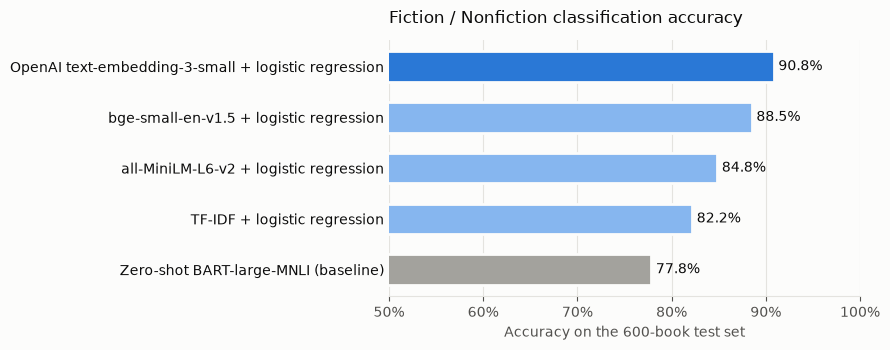

In [10]:
SURFACE, INK, INK_MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
HIGHLIGHT, OTHER, BASELINE = "#2a78d6", "#86b6ef", "#a3a29d"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED, "ytick.color": INK,
    "text.color": INK, "font.size": 10,
})

plot_data = test_results.sort_values("test accuracy")
colors = [HIGHLIGHT if sel else BASELINE if "baseline" in m else OTHER
          for m, sel in zip(plot_data["model"], plot_data["selected by CV"])]

fig, ax = plt.subplots(figsize=(9, 3.6))
bars = ax.barh(plot_data["model"], plot_data["test accuracy"], color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
for bar, value in zip(bars, plot_data["test accuracy"]):
    ax.text(value + 0.005, bar.get_y() + bar.get_height() / 2, f"{value:.1%}", va="center", color=INK, fontsize=10)

ax.set_xlim(0.5, 1.0)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.set_xlabel("Accuracy on the 600-book test set")
ax.set_title("Fiction / Nonfiction classification accuracy", loc="left", fontsize=12, color=INK, pad=12)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.savefig("../screenshots/classifier-accuracy.png", dpi=150, facecolor=SURFACE)
plt.show()

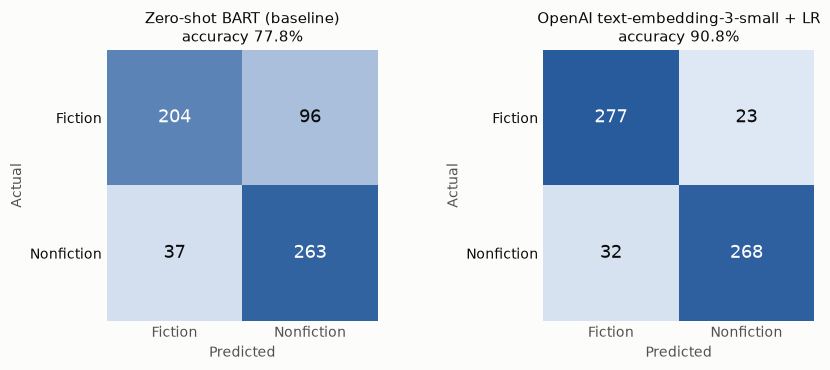

In [11]:
cmap = LinearSegmentedColormap.from_list("blue", ["#eef4fc", "#184f95"])
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))

for ax, (title, pred) in zip(axes, [("Zero-shot BART (baseline)", zero_shot_pred),
                                    (f"{best['features']} + LR", best_pred)]):
    cm = confusion_matrix(y_test, pred, labels=[1, 0])
    ax.imshow(cm, cmap=cmap, vmin=0, vmax=300)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=13,
                    color="#ffffff" if cm[i, j] > 150 else INK)
    ax.set_xticks([0, 1], ["Fiction", "Nonfiction"])
    ax.set_yticks([0, 1], ["Fiction", "Nonfiction"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(f"{title}\naccuracy {accuracy_score(y_test, pred):.1%}", fontsize=11, color=INK)
    for spine in ax.spines.values():
        spine.set_visible(False)
    ax.tick_params(length=0)

plt.tight_layout()
plt.show()

### Where the new model still goes wrong

In [12]:
errors = test.assign(actual=np.where(y_test == 1, "Fiction", "Nonfiction"),
                     predicted=np.where(best_pred == 1, "Fiction", "Nonfiction"))
errors = errors[errors["actual"] != errors["predicted"]]
print(f"{len(errors)} misclassified books, e.g.:")
errors[["title", "categories", "actual", "predicted", "description"]].head(8).assign(
    description=lambda d: d["description"].str.slice(0, 140) + "..."
)

55 misclassified books, e.g.:


,title,categories,actual,predicted,description
132,Warrior of the Light,Fiction,Fiction,Nonfiction,Warrior of the Light: A Manual is an inspirati...
227,Holy Skirts,Fiction,Fiction,Nonfiction,No one in 1917 New York had ever encountered a...
230,Cracks in My Foundation,Fiction,Fiction,Nonfiction,Go further under the covers and stay in bed a ...
269,How to Make Money Like a Porn Star,Comics & Graphic Novels,Fiction,Nonfiction,Claudia Corvette. From her tousled bedroom hai...
286,Jonah's Gourd Vine,Fiction,Fiction,Nonfiction,"John Buddy Pearson, a young Black man who beco..."
362,Their Eyes Were Watching God,Fiction,Fiction,Nonfiction,One of the most important works of twentieth-c...
376,Days,Fiction,Fiction,Nonfiction,"Between 1987 and 1989, Paul Bowles, at the sug..."
377,Howl,Poetry,Fiction,Nonfiction,A special anniversary edition of the first pub...


## 6. Re-label the uncategorised books

The selected configuration is retrained on **every labelled book** (training + test) and used to label the
1,454 books that had no category. The results replace the zero-shot labels in the processed data files, so the
dashboard's category filter uses them automatically. The emotion scores are not affected.

In [13]:
all_labelled = pd.concat([training_books(best["children's books"]), test])
class_weight = None if best["class weight"] == "none" else best["class weight"]
final_model, final_vectorizer = fit_model(best["features"], all_labelled.index, all_labelled["is_fiction"].astype(int), class_weight)

new_labels = pd.Series(
    np.where(final_model.predict(make_matrix(best["features"], unlabelled.index, final_vectorizer)) == 1, "Fiction", "Nonfiction"),
    index=unlabelled["isbn13"].values,
)

old = pd.read_csv(PROCESSED / "books_cleaned_with_categories.csv").set_index("isbn13")
old_labels = old.loc[new_labels.index, "simple_categories"]
changed = (old_labels != new_labels).sum()
print(f"Re-labelled {len(new_labels)} books. {changed} labels changed "
      f"({changed / len(new_labels):.1%}); agreement with zero-shot {1 - changed / len(new_labels):.1%}.")
pd.crosstab(old_labels.rename("zero-shot label"), new_labels.rename("new label"))

Re-labelled 1454 books. 307 labels changed (21.1%); agreement with zero-shot 78.9%.


new label,Fiction,Nonfiction
zero-shot label,,
Fiction,381,63
Nonfiction,244,766


In [14]:
for file_name in ["books_cleaned_with_categories.csv", "books_with_emotions.csv"]:
    path = PROCESSED / file_name
    df = pd.read_csv(path, dtype=str, keep_default_na=False)  # text in, text out: only the category changes
    mask = df["isbn13"].astype(int).isin(new_labels.index)
    df.loc[mask, "simple_categories"] = df.loc[mask, "isbn13"].astype(int).map(new_labels)
    df.to_csv(path, index=False)
    print(f"Updated {mask.sum()} rows in {file_name}")

Updated 1454 rows in books_cleaned_with_categories.csv


Updated 1454 rows in books_with_emotions.csv


## 7. Summary

| Model | Test accuracy |
|---|---|
| Zero-shot BART-large-MNLI (baseline) | 77.8% |
| TF-IDF + logistic regression | 82.2% |
| all-MiniLM-L6-v2 + logistic regression | 84.8% |
| bge-small-en-v1.5 + logistic regression | 88.5% |
| **OpenAI text-embedding-3-small + logistic regression** | **90.8%** |

- A logistic regression on the **OpenAI embeddings already stored for search** improves accuracy from
  **77.8% to 90.8%** on the same 600 test books (+13.0 points, 95% CI +9.3 to +16.7, McNemar p = 7e-12).
  It needed no new API calls and trains in seconds.
- It was chosen by cross-validation on the training set (balanced accuracy 91.6%), and the test score agrees.
- Zero-shot mostly failed by calling **Fiction books Nonfiction** (96 of 300). The new model's errors are
  spread more evenly (23 and 32).
- Weighting the classes equally helped every feature set. Adding children's books as extra training data
  did not help.
- Remaining errors are mostly books whose descriptions read like the other class, such as literary novels
  described through their real-life history (*Their Eyes Were Watching God*) or inspirational fiction
  (*Warrior of the Light*).
- Re-labelling the 1,454 uncategorised books changed **307 labels (21%)**, most of them
  Nonfiction to Fiction (244), matching the zero-shot model's bias.
